In [1]:
import os, sys
sys.path.insert(0, os.path.abspath(os.path.join("..", "hil_bench")))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
import analysis as A, params as P, pr_design as D
claims = []
def claim(cid, text, number, source):
    claims.append({"ID": cid, "Claim": text, "Number": number, "Source": source})
NBID = "06"

# 06 · Condition 3: it needs enough DC voltage, and time

**Question:** pushing harmonic current into a weak grid needs harmonic voltage from the bridge. When does
the bridge run out of voltage?

**First look (sweep).** The "vdc" sweep stepped the DC voltage on SCR 10 and SCR 5 and measured 3 s
after each step. At SCR 5 it gave large and unrepeatable errors, even at 850 V.

**Second look (hold tests, HIL404).** `saturation_hold.py` steps the grid from SCR 20 to SCR 5 at a fixed
DC voltage, then **keeps measuring every 5-15 s for up to 2 minutes**.

| DC voltage, V | first capture, s | error then, % | last capture, s | error at the end, % |
|---|---|---|---|---|
| 650 | 12.2 | 52.3 | 120 | 127 |
| 700 | 17.3 | 20.6 | 121 | 12.5 |
| 725 | 17 | 11.3 | 136 | 0.31 |
| 750 | 7.08 | 16.2 | 92.4 | 0.23 |
| 850 | 7.06 | 1.82 | 92.4 | 0.261 |

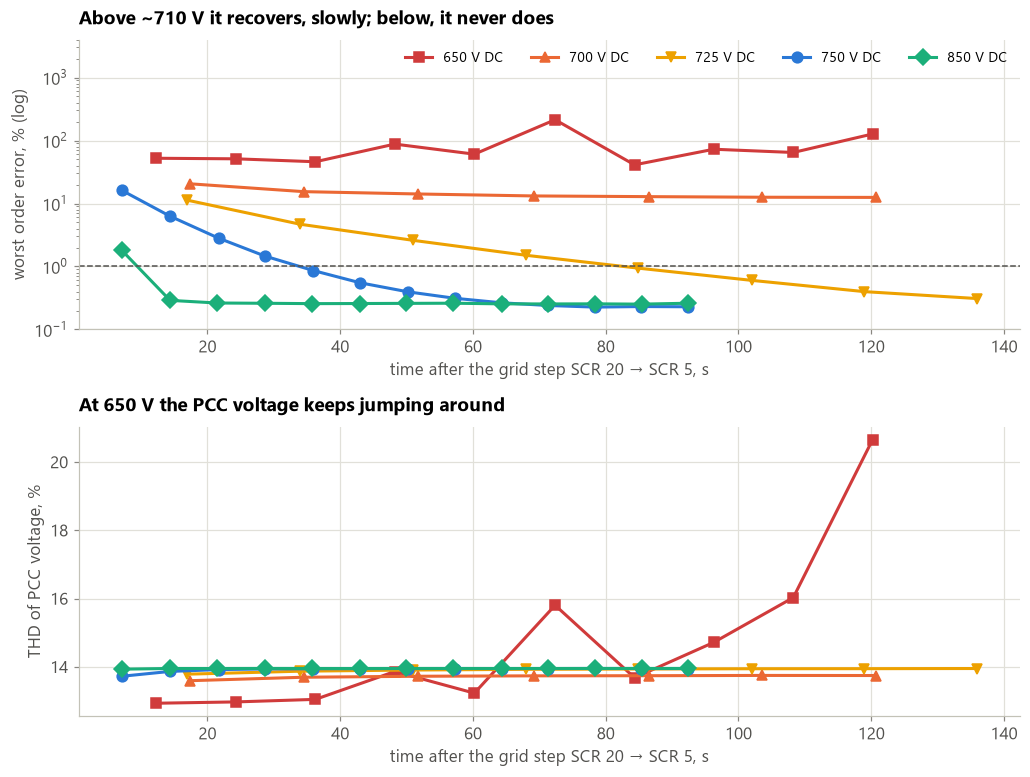

In [2]:
volts = [650, 700, 725, 750, 850]
col = {650: A.BAD, 700: A.OTHER, 725: "#eda100", 750: A.USED, 850: "#1baf7a"}
mk = {650: "s", 700: "^", 725: "v", 750: "o", 850: "D"}
fig, ax = A.panels(2, h=3.6)
rows = []
for v in volts:
    x = A.load("saturation_hold_hil404_SCR5_%d.csv" % v)
    ax[0].plot(x.t_after_step_s, x.worst_order_error_pct, mk[v] + "-", color=col[v], label="%d V DC" % v)
    ax[1].plot(x.t_after_step_s, x.THD_V_pct, mk[v] + "-", color=col[v], label="%d V DC" % v)
    rows.append(x.assign(vdc=v))
ax[0].set_yscale("log"); ax[0].axhline(1, color=A.LIMIT, ls="--", lw=1)
ax[0].set_ylabel("worst order error, % (log)"); ax[0].set_xlabel("time after the grid step SCR 20 → SCR 5, s")
ax[0].set_title("Above ~710 V it recovers, slowly; below, it never does")
ax[0].set_ylim(0.1, 4000); ax[0].legend(ncol=5, loc="upper right", fontsize=9)
ax[1].set_ylabel("THD of PCC voltage, %"); ax[1].set_xlabel("time after the grid step SCR 20 → SCR 5, s")
ax[1].set_title("At 650 V the PCC voltage keeps jumping around")
hold = pd.concat(rows)
A.save(fig, "06_hold_tests", hold)
last = hold.sort_values("t_after_step_s").groupby("vdc").tail(1).set_index("vdc")
first = hold.sort_values("t_after_step_s").groupby("vdc").head(1).set_index("vdc")
t = pd.DataFrame({"DC voltage, V": volts, "first capture, s": [first.t_after_step_s[v] for v in volts],
                  "error then, %": [first.worst_order_error_pct[v] for v in volts],
                  "last capture, s": [last.t_after_step_s[v] for v in volts], "error at the end, %": [last.worst_order_error_pct[v] for v in volts]})
display(Markdown(A.md_table(t)))
claim("C6.1", "SCR 5, full request (HIL404): error at the end of the hold at 850 / 750 / 725 V",
      " / ".join("%.2f %%" % last.worst_order_error_pct[v] for v in (850, 750, 725)), "results/saturation_hold_hil404_SCR5_*.csv")
claim("C6.2", "SCR 5, full request, 700 V: steady error (does not recover)", "%.1f %%" % last.worst_order_error_pct[700], "results/saturation_hold_hil404_SCR5_700.csv")
claim("C6.3", "SCR 5, full request, 650 V: error range and largest THD_V over the hold",
      "%.0f-%.0f %%, THD_V up to %.1f %%" % (hold[(hold.vdc == 650) & (hold.t_after_step_s > 30)].worst_order_error_pct.min(),
                                           hold[hold.vdc == 650].worst_order_error_pct.max(), hold[hold.vdc == 650].THD_V_pct.max()),
      "results/saturation_hold_hil404_SCR5_650.csv")

**Reading.** Each line is one DC voltage. Right after the grid step every case is far off. Then:

- **850 V, 750 V, 725 V**: the error comes down below 1 % and settles around 0.2-0.3 %, but it takes
  15 s to 2 minutes. The more DC voltage, the faster.
- **700 V**: settles at a steady error of about 12 % (the 37th order is short). The bridge is out of voltage.
- **650 V**: never settles; the error and the PCC voltage jump around.

So the steady limit at SCR 5 with full emission is between 700 and 725 V (about 710 V).

## Where the first look went wrong

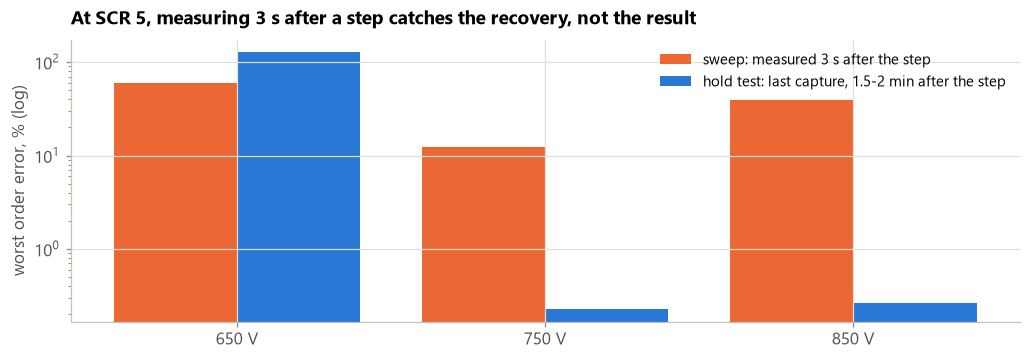

In [3]:
p = A.load("sweep_hil404_points.csv")
sv = p[(p.sweep == "vdc") & (p.grid == "SCR 5")].set_index("vdc")
cmp = pd.DataFrame({"DC voltage, V": [650, 750, 850],
                    "sweep (3 s after step), %": [sv.worst_order_error_pct[v] for v in (650, 750, 850)],
                    "hold test, end, %": [last.worst_order_error_pct[v] for v in (650, 750, 850)]})
fig, ax = A.panels(1, h=3.4)
xx = np.arange(3)
ax[0].bar(xx - 0.2, cmp.iloc[:, 1], 0.4, color=A.OTHER, label="sweep: measured 3 s after the step")
ax[0].bar(xx + 0.2, cmp.iloc[:, 2], 0.4, color=A.USED, label="hold test: last capture, 1.5-2 min after the step")
ax[0].set_yscale("log"); ax[0].set_xticks(xx); ax[0].set_xticklabels(["650 V", "750 V", "850 V"])
ax[0].set_ylabel("worst order error, % (log)"); ax[0].legend()
ax[0].set_title("At SCR 5, measuring 3 s after a step catches the recovery, not the result")
A.save(fig, "06_sweep_vs_hold", cmp)
sc10 = A.load("saturation_hold_hil404_SCR10_650.csv")
claim("C6.4", "SCR 10 at 650 V, full request (HIL404): error at the end of the hold", "%.2f %%" % sc10.worst_order_error_pct.iloc[-1], "results/saturation_hold_hil404_SCR10_650.csv")

**Reading.** At 750 V and 850 V the sweep reported big errors because it measured too early. Only 650 V
is truly bad. On SCR 10 even 650 V settles (to about 0.3 %).

**Why so slow?** The controller design trades speed for stability on every grid (time constant about
0.4 s on SCR 5, notebook 04). After a step the bridge briefly hits its voltage limit, and the resonant terms
keep integrating while it does (there is no anti-windup), so they overshoot and take a long time to unwind.
Adding anti-windup is an obvious improvement.

## Rule for users
- Full emission at SCR 5: use **at least 750 V DC**, and wait **about 1-2 minutes** after a grid or DC step.
- On SCR 10 and stronger grids, 750 V is plenty; 3 s settle is enough.
- If in doubt, use `saturation_hold.py` to watch the error settle.

## Limits of this notebook
- Hold tests were run at SCR 5 (650-850 V) and SCR 10 (650 V) only, with the full request.

In [4]:
c = pd.DataFrame(claims)
c.to_csv(os.path.join(A.FIG, "claims_%s.csv" % NBID), index=False)
display(Markdown(A.md_table(c)))

| ID | Claim | Number | Source |
|---|---|---|---|
| C6.1 | SCR 5, full request (HIL404): error at the end of the hold at 850 / 750 / 725 V | 0.26 % / 0.23 % / 0.31 % | results/saturation_hold_hil404_SCR5_*.csv |
| C6.2 | SCR 5, full request, 700 V: steady error (does not recover) | 12.5 % | results/saturation_hold_hil404_SCR5_700.csv |
| C6.3 | SCR 5, full request, 650 V: error range and largest THD_V over the hold | 41-214 %, THD_V up to 20.7 % | results/saturation_hold_hil404_SCR5_650.csv |
| C6.4 | SCR 10 at 650 V, full request (HIL404): error at the end of the hold | 0.28 % | results/saturation_hold_hil404_SCR10_650.csv |